In [1]:
import warnings
import itertools

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import stats

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

warnings.filterwarnings("ignore")

In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "code":
    BASE_DIR = CURRENT_DIR.parent
else:
    BASE_DIR = CURRENT_DIR

DATA_DIR = BASE_DIR / "data" / "processed"
FIGURE_DIR = BASE_DIR / "figures"
RESULT_DIR = BASE_DIR / "results"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# ============================================================
# 1. ĐỌC DỮ LIỆU
# ============================================================

price_train = pd.read_csv(DATA_DIR / "price_train.csv", parse_dates=["Date"])
price_val = pd.read_csv(DATA_DIR / "price_validation.csv", parse_dates=["Date"])
price_test = pd.read_csv(DATA_DIR / "price_test.csv", parse_dates=["Date"])

price_all = (
    pd.concat([price_train, price_val, price_test])
    .sort_values("Date")
    .reset_index(drop=True)
)

# Mô hình hóa y = 100 * log(price)
# -> sai phân bậc 1 của y chính là log-return (%), cùng đơn vị với cột log_return trong dữ liệu đã xử lý
y_all = price_all["log_price"].values * 100

n_train = len(price_train)
n_val = len(price_val)
n_test = len(price_test)

y_train = y_all[:n_train]
y_train_val = y_all[:n_train + n_val]

print("Train:", n_train, "| Validation:", n_val, "| Test:", n_test)

Train: 2347 | Validation: 262 | Test: 175


Sai lệch lớn nhất giữa diff(100*log_price) và log_return: 5.672129432809925e-13


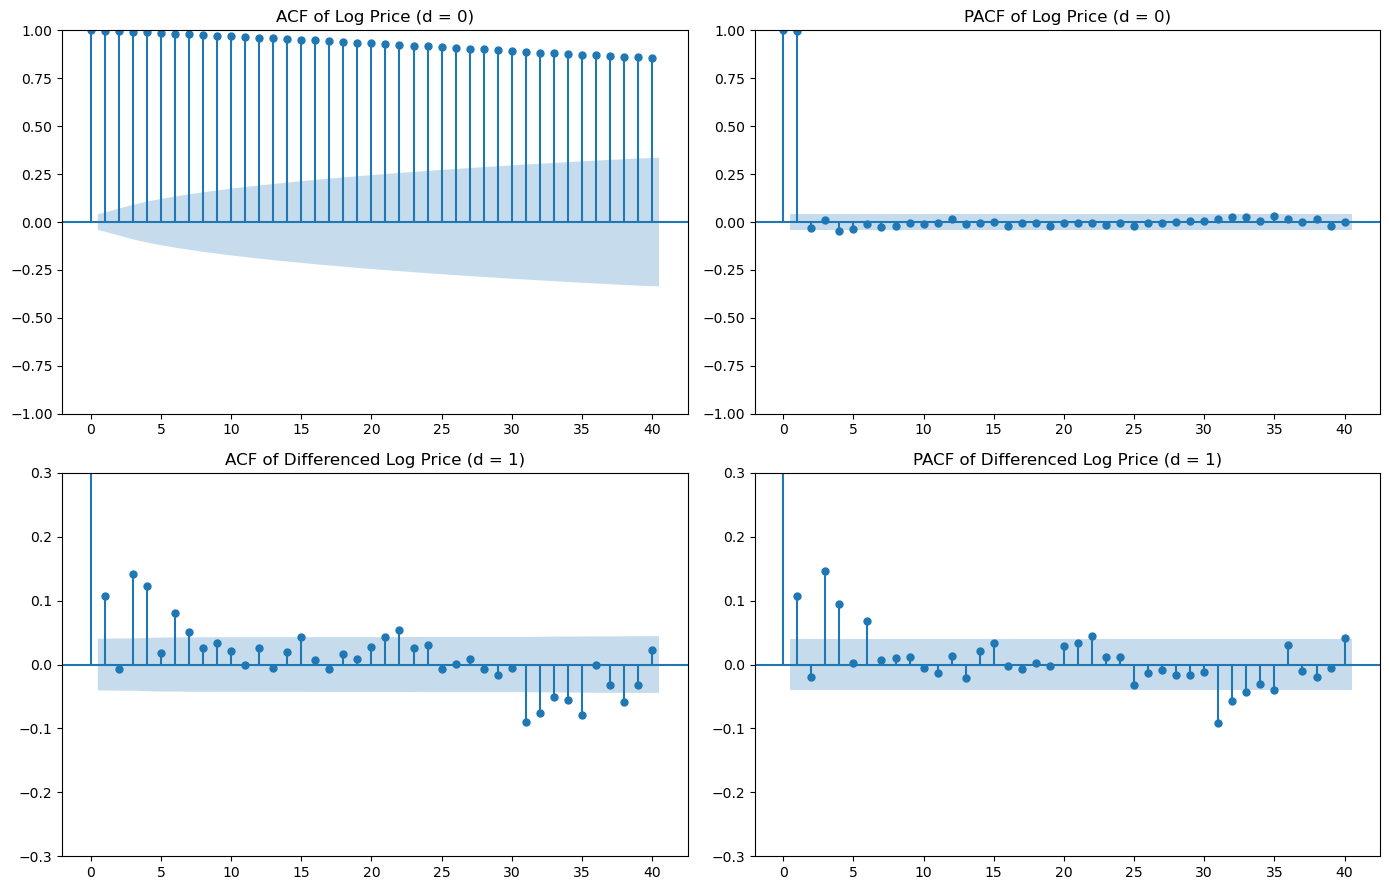


Ngưỡng 95%: ± 0.0405
Lag ACF vượt ngưỡng : [1, 3, 4, 6, 7, 15, 21, 22, 31, 32, 33, 34, 35, 38]
Lag PACF vượt ngưỡng: [1, 3, 4, 6, 22, 31, 32, 33, 40]

 d    N  ADF statistic  ADF p-value  KPSS statistic  KPSS p-value (bounded 0.01-0.10)
 0 2347        -0.4125        0.908          5.1178                              0.01
 1 2346       -15.6039        0.000          0.1402                              0.10


In [4]:
# ============================================================
# 2. NHẬN DẠNG MÔ HÌNH (BOX-JENKINS)
# ============================================================
# Chuỗi đầu vào: log_price và sai phân bậc 1 của log_price

diff_train = np.diff(y_train)   # = 100 * (log P_t - log P_{t-1})

# Kiểm tra: sai phân của 100·log_price trùng với cột log_return trong data/processed/return_train.csv
return_train = pd.read_csv(DATA_DIR / "return_train.csv")

print(
    "Sai lệch lớn nhất giữa diff(100*log_price) và log_return:",
    np.max(np.abs(diff_train - return_train["log_return"].values))
)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

plot_acf(y_train, lags=40, ax=ax[0, 0])
ax[0, 0].set_title("ACF of Log Price (d = 0)")

plot_pacf(y_train, lags=40, method="ywm", ax=ax[0, 1])
ax[0, 1].set_title("PACF of Log Price (d = 0)")

plot_acf(diff_train, lags=40, ax=ax[1, 0])
ax[1, 0].set_title("ACF of Differenced Log Price (d = 1)")

plot_pacf(diff_train, lags=40, method="ywm", ax=ax[1, 1])
ax[1, 1].set_title("PACF of Differenced Log Price (d = 1)")

for a in ax[1]:
    a.set_ylim(-0.3, 0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "10_arima_identification.png",
    dpi=300
)

plt.show()

# Các lag có ACF / PACF vượt ngưỡng 95% của chuỗi sai phân
bound = 1.96 / np.sqrt(len(diff_train))

acf_values = acf(diff_train, nlags=40)[1:]
pacf_values = pacf(diff_train, nlags=40, method="ywm")[1:]

print("\nNgưỡng 95%: ±", round(bound, 4))
print("Lag ACF vượt ngưỡng :", list(np.where(np.abs(acf_values) > bound)[0] + 1))
print("Lag PACF vượt ngưỡng:", list(np.where(np.abs(pacf_values) > bound)[0] + 1))

# Kiểm định tính dừng bổ sung cho ADF: ADF (H0: nghiệm đơn vị) và KPSS (H0: dừng), cùng hằng số
# KPSS chỉ tra bảng giá trị tới hạn trong [0,01; 0,10], nên p-value ở biên có nghĩa là < 0,01 hoặc > 0,10
stationarity_rows = []

for d_, series_ in [(0, y_train), (1, diff_train)]:

    adf_stat, adf_p = adfuller(series_, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(series_, regression="c", nlags="auto")[:2]

    stationarity_rows.append({
        "d": d_,
        "N": len(series_),
        "ADF statistic": adf_stat,
        "ADF p-value": adf_p,
        "KPSS statistic": kpss_stat,
        "KPSS p-value (bounded 0.01-0.10)": kpss_p
    })

stationarity_table = pd.DataFrame(stationarity_rows)
stationarity_table.to_csv(RESULT_DIR / "arima_stationarity_tests.csv", index=False)

print()
print(stationarity_table.round(4).to_string(index=False))

In [5]:
# ============================================================
# 3. CÓ CẦN HẰNG SỐ (DRIFT) KHÔNG?
# ============================================================
# H0: E[diff log price] = 0
# Lưu ý: t-test giả định các quan sát độc lập; return có tự tương quan và đuôi dày
# nên p-value chỉ mang tính tham khảo. Drift không ổn định giữa các năm nên không đưa vào mô hình.

t_stat, p_value = stats.ttest_1samp(diff_train, 0)

print("Mean diff log price (%):", diff_train.mean())
print("t-stat:", t_stat)
print("p-value:", p_value)

Mean diff log price (%): 0.005445951272015185
t-stat: 1.967891658841537
p-value: 0.04919817026654566


In [6]:
# ============================================================
# 4. CHỌN BẬC ARIMA(p, 1, q) TRÊN TẬP TRAIN
# ============================================================
# d = 1 theo ADF và KPSS ở mục 2: log-price không dừng, sai phân bậc 1 dừng
# trend = "n": không đưa hằng số drift (xem mục 3)

order_rows = []

for p, q in itertools.product(range(5), range(5)):

    res = ARIMA(
        y_train,
        order=(p, 1, q),
        trend="n"
    ).fit()

    order_rows.append({
        "p": p,
        "d": 1,
        "q": q,
        "AIC": res.aic,
        "BIC": res.bic,
        "Log-likelihood": res.llf
    })

order_table = pd.DataFrame(order_rows)

order_table.to_csv(
    RESULT_DIR / "arima_order_selection.csv",
    index=False
)

print("TOP 5 THEO AIC")
print(order_table.sort_values("AIC").head(5).to_string(index=False))

print("\nTOP 5 THEO BIC")
print(order_table.sort_values("BIC").head(5).to_string(index=False))

TOP 5 THEO AIC
 p  d  q          AIC          BIC  Log-likelihood
 3  1  4 -2866.228328 -2820.144592     1441.114164
 4  1  3 -2865.911888 -2819.828152     1440.955944
 4  1  2 -2865.509950 -2825.186681     1439.754975
 4  1  4 -2864.140977 -2812.296774     1441.070488
 3  1  3 -2863.204306 -2822.881037     1438.602153

TOP 5 THEO BIC
 p  d  q          AIC          BIC  Log-likelihood
 3  1  1 -2862.551826 -2833.749491     1436.275913
 4  1  0 -2860.157222 -2831.354886     1435.078611
 1  1  3 -2857.892851 -2829.090516     1433.946426
 4  1  1 -2860.552726 -2825.989924     1436.276363
 3  1  2 -2860.552240 -2825.989438     1436.276120


In [7]:
# Ứng viên (cố định trước khi xem Validation/Test):
# 5 mô hình tốt nhất theo AIC, 5 mô hình tốt nhất theo BIC và 4 mô hình bậc thấp
best_aic = order_table.loc[order_table["AIC"].idxmin()]
best_bic = order_table.loc[order_table["BIC"].idxmin()]

top_ic = pd.concat([order_table.nsmallest(5, "AIC"), order_table.nsmallest(5, "BIC")])

candidates = [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1)] + [
    (int(r.p), 1, int(r.q)) for r in top_ic.itertuples()
]

candidates = list(dict.fromkeys(candidates))

print("Best AIC:", (int(best_aic["p"]), 1, int(best_aic["q"])))
print("Best BIC:", (int(best_bic["p"]), 1, int(best_bic["q"])))
print("Ứng viên:", candidates)

Best AIC: (3, 1, 4)
Best BIC: (3, 1, 1)
Ứng viên: [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1), (3, 1, 4), (4, 1, 3), (4, 1, 2), (4, 1, 4), (3, 1, 3), (3, 1, 1), (4, 1, 0), (1, 1, 3), (4, 1, 1), (3, 1, 2)]


In [8]:
# ============================================================
# 5. KIỂM TRA OVERFITTING
# ============================================================
# (a) Các mô hình bậc thấp: thêm một bậc AR hoặc MA vào AR(1), MA(1) để xem phụ thuộc nằm ở độ trễ nào.
#     Nếu tham số thêm vào không có ý nghĩa thống kê -> giữ mô hình gọn hơn.
# (b) Kiểm tra overfitting cho mô hình được chọn nằm ở mục 9 (sau khi đã chọn ở mục 8).

overfit_rows = []

for order in [(1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 0), (0, 1, 2)]:

    res = ARIMA(y_train, order=order, trend="n").fit()

    for name in res.param_names:

        if name == "sigma2":
            continue

        overfit_rows.append({
            "Model": f"ARIMA{order}",
            "Parameter": name,
            "Estimate": res.params[res.param_names.index(name)],
            "Std. error": res.bse[res.param_names.index(name)],
            "p-value": res.pvalues[res.param_names.index(name)],
            "AIC": res.aic,
            "BIC": res.bic
        })

overfit_table = pd.DataFrame(overfit_rows)

overfit_table.to_csv(
    RESULT_DIR / "arima_overfitting.csv",
    index=False
)

print(overfit_table.round(4).to_string(index=False))

         Model Parameter  Estimate  Std. error  p-value        AIC        BIC
ARIMA(1, 1, 0)     ar.L1    0.1088      0.0106   0.0000 -2792.5204 -2780.9995
ARIMA(0, 1, 1)     ma.L1    0.1167      0.0107   0.0000 -2794.1289 -2782.6080
ARIMA(1, 1, 1)     ar.L1   -0.3437      0.0782   0.0000 -2797.8750 -2780.5936
ARIMA(1, 1, 1)     ma.L1    0.4593      0.0736   0.0000 -2797.8750 -2780.5936
ARIMA(2, 1, 0)     ar.L1    0.1107      0.0108   0.0000 -2791.2782 -2773.9968
ARIMA(2, 1, 0)     ar.L2   -0.0180      0.0102   0.0793 -2791.2782 -2773.9968
ARIMA(0, 1, 2)     ma.L1    0.1192      0.0106   0.0000 -2794.4045 -2777.1231
ARIMA(0, 1, 2)     ma.L2   -0.0280      0.0101   0.0058 -2794.4045 -2777.1231


In [9]:
# ============================================================
# 6. HÀM DỰ BÁO 1 BƯỚC (ROLLING ONE-STEP-AHEAD)
# ============================================================
# Ước lượng tham số trên fit_series, giữ cố định tham số,
# rồi lọc qua full_series để dự báo y[t] từ thông tin đến t-1.

def one_step_forecast(order, fit_series, full_series, start):

    res = ARIMA(fit_series, order=order, trend="n").fit()

    res_full = res.apply(full_series)

    pred = res_full.get_prediction(start=start)

    ci = pred.conf_int(alpha=0.05)

    return res, pred.predicted_mean, ci[:, 0], ci[:, 1]


def diebold_mariano(e_model, e_bench):
    """
    DM test (h = 1), loss = sai số bình phương, phương sai mẫu thông thường (không HAC).
    Chỉ dùng cho bảng sàng lọc ở mục 7 và mục 15.6; kiểm định chính dùng hac_test() ở mục 11.
    H0: hai mô hình có độ chính xác như nhau
    DM < 0: mô hình tốt hơn benchmark
    """

    d = e_model ** 2 - e_bench ** 2

    dm = d.mean() / np.sqrt(d.var(ddof=1) / len(d))

    p_value = 2 * (1 - stats.norm.cdf(abs(dm)))

    return dm, p_value


def evaluate(name, y_true, y_prev, y_pred, lower, upper, y_pred_rw):

    ret_true = y_true - y_prev
    ret_pred = y_pred - y_prev
    ret_rw = y_pred_rw - y_prev

    price_true = np.exp(y_true / 100)
    price_pred = np.exp(y_pred / 100)

    price_lower = np.exp(lower / 100)
    price_upper = np.exp(upper / 100)

    rmse_ret = np.sqrt(np.mean((ret_true - ret_pred) ** 2))
    rmse_rw = np.sqrt(np.mean((ret_true - ret_rw) ** 2))

    # Độ chính xác dấu: chỉ tính khi mô hình dự báo return khác 0
    nonzero = np.abs(ret_pred) > 1e-10

    if nonzero.sum() > 0:
        direction = np.mean(
            np.sign(ret_pred[nonzero]) == np.sign(ret_true[nonzero])
        )
    else:
        direction = np.nan

    if np.allclose(ret_pred, ret_rw):
        dm, dm_p = np.nan, np.nan
    else:
        dm, dm_p = diebold_mariano(ret_true - ret_pred, ret_true - ret_rw)

    return {
        "Model": name,
        "RMSE return (%)": rmse_ret,
        "MAE return (%)": np.mean(np.abs(ret_true - ret_pred)),
        "Theil U (vs RW)": rmse_ret / rmse_rw,
        "Direction accuracy": direction,
        "RMSE price": np.sqrt(np.mean((price_true - price_pred) ** 2)),
        "MAE price": np.mean(np.abs(price_true - price_pred)),
        "MAPE price (%)": np.mean(np.abs((price_true - price_pred) / price_true)) * 100,
        "95% CI coverage": np.mean((price_true >= price_lower) & (price_true <= price_upper)),
        "DM stat": dm,
        "DM p-value": dm_p
    }

In [10]:
# ============================================================
# 7. SO SÁNH CÁC ỨNG VIÊN TRÊN TẬP VALIDATION
# ============================================================
# Tham số ước lượng trên train, dự báo 1 bước cho từng ngày của 2025

y_val_true = y_all[n_train:n_train + n_val]
y_val_prev = y_all[n_train - 1:n_train + n_val - 1]

# Random walk: dự báo hôm nay = giá hôm qua
y_val_rw = y_val_prev

val_rows = []

for order in candidates:

    res, y_pred, lower, upper = one_step_forecast(
        order,
        y_train,
        y_train_val,
        start=n_train
    )

    row = evaluate(
        f"ARIMA{order}",
        y_val_true,
        y_val_prev,
        y_pred,
        lower,
        upper,
        y_val_rw
    )

    # Điều kiện hợp lệ của mô hình ước lượng trên Train
    k = order[0] + order[2]
    resid = res.resid[1:]
    lb = acorr_ljungbox(resid, lags=[10, 20], model_df=k)["lb_pvalue"].values

    row.update({
        "p + q": k,
        "Converged": bool(res.mle_retvals.get("converged", True)) if res.mle_retvals else True,
        "Roots OK": bool(np.all(np.abs(res.arroots) > 1) and np.all(np.abs(res.maroots) > 1)),
        "LB(10) p adj": lb[0],
        "LB(20) p adj": lb[1]
    })

    val_rows.append(row)

val_table = pd.DataFrame(val_rows)


print(val_table.round(4).to_string(index=False))

         Model  RMSE return (%)  MAE return (%)  Theil U (vs RW)  Direction accuracy  RMSE price  MAE price  MAPE price (%)  95% CI coverage  DM stat  DM p-value  p + q  Converged  Roots OK  LB(10) p adj  LB(20) p adj
ARIMA(0, 1, 0)           0.1686          0.0975           1.0000                 NaN     43.2528    25.1870          0.0975           0.9237      NaN         NaN      0       True      True        0.0000        0.0000
ARIMA(1, 1, 0)           0.1698          0.0981           1.0074              0.5000     43.5712    25.3362          0.0980           0.9313   0.7769      0.4372      1       True      True        0.0000        0.0000
ARIMA(0, 1, 1)           0.1696          0.0981           1.0059              0.4809     43.5045    25.3337          0.0980           0.9313   0.5606      0.5751      1       True      True        0.0000        0.0000
ARIMA(1, 1, 1)           0.1683          0.0985           0.9982              0.4771     43.1741    25.4339          0.0984     

In [11]:
# ============================================================
# 8. CHỌN MÔ HÌNH CUỐI CÙNG
# ============================================================
# Quy tắc chọn (cố định trước khi đánh giá Test):
#  (1) chỉ xét mô hình hội tụ, nghiệm AR/MA ngoài đường tròn đơn vị,
#      Ljung-Box phần dư Train (trừ bậc tự do p + q) có p > 0,05 ở lag 10 và 20;
#  (2) trong nhóm có RMSE tỷ giá Validation không vượt quá 1% so với mức tốt nhất,
#      chọn mô hình ít tham số nhất (p + q nhỏ nhất); hòa thì lấy RMSE nhỏ hơn.

val_table["Order"] = candidates

eligible = val_table[
    val_table["Converged"] & val_table["Roots OK"]
    & (val_table["LB(10) p adj"] > 0.05) & (val_table["LB(20) p adj"] > 0.05)
]

best_rmse = eligible["RMSE price"].min()

near_best = eligible[eligible["RMSE price"] <= 1.01 * best_rmse]

chosen = near_best.sort_values(["p + q", "RMSE price"]).iloc[0]

final_order = chosen["Order"]

cols = ["Model", "RMSE price", "MAE price", "Theil U (vs RW)", "DM p-value", "p + q", "Converged", "Roots OK", "LB(10) p adj", "LB(20) p adj"]

print("Ứng viên hợp lệ, sắp theo RMSE tỷ giá:")
print(eligible.sort_values("RMSE price")[cols].round(4).to_string(index=False))
print()
print(f"Ngưỡng 1%: RMSE <= {1.01 * best_rmse:.4f}")
print("Mô hình cuối:", final_order)

val_table.drop(columns="Order").to_csv(RESULT_DIR / "arima_validation_metrics.csv", index=False)

# Mô hình tốt nhất theo AIC (để so sánh / chẩn đoán)
aic_order = (int(best_aic["p"]), 1, int(best_aic["q"]))

Ứng viên hợp lệ, sắp theo RMSE tỷ giá:
         Model  RMSE price  MAE price  Theil U (vs RW)  DM p-value  p + q  Converged  Roots OK  LB(10) p adj  LB(20) p adj
ARIMA(3, 1, 4)     42.9528    25.9648           0.9929      0.7341      7       True      True        0.9041        0.9028
ARIMA(3, 1, 1)     43.1262    25.9495           0.9968      0.8687      4       True      True        0.1604        0.3890
ARIMA(3, 1, 2)     43.1269    25.9498           0.9968      0.8694      5       True      True        0.0998        0.3220
ARIMA(4, 1, 1)     43.1278    25.9497           0.9968      0.8702      5       True      True        0.0998        0.3221
ARIMA(4, 1, 0)     43.1701    26.1015           0.9978      0.9131      4       True      True        0.0742        0.2417

Ngưỡng 1%: RMSE <= 43.3823
Mô hình cuối: (3, 1, 1)


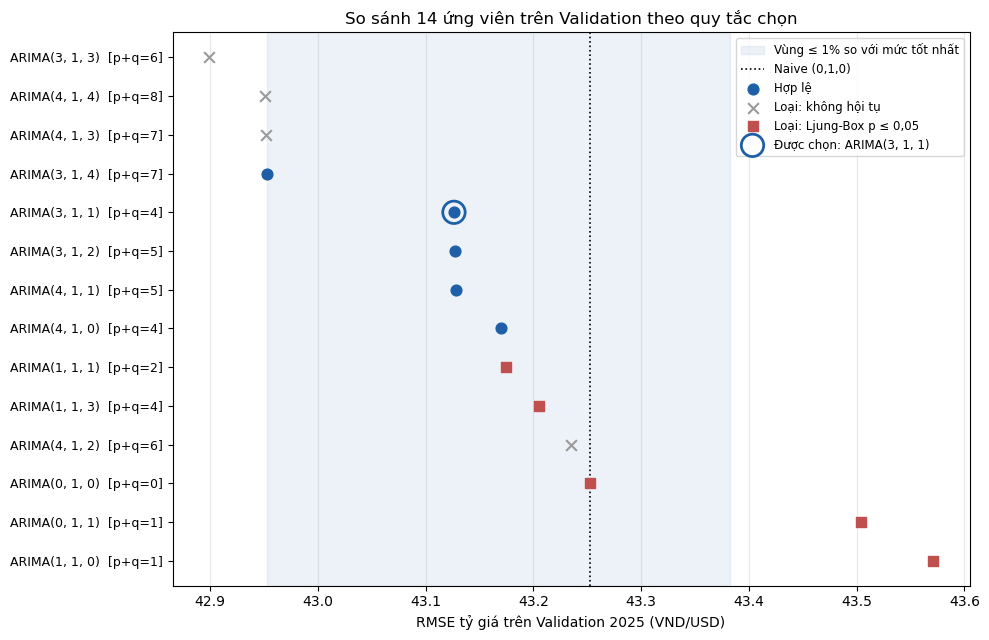

In [12]:
# ------------------------------------------------------------
# Hình 22: RMSE tỷ giá trên Validation của 14 ứng viên và lý do loại
# ------------------------------------------------------------

def status_of(row):
    if not row["Converged"]:
        return "Loại: không hội tụ"
    if not row["Roots OK"]:
        return "Loại: nghiệm trong đường tròn đơn vị"
    if row["LB(10) p adj"] <= 0.05 or row["LB(20) p adj"] <= 0.05:
        return "Loại: Ljung-Box p ≤ 0,05"
    return "Hợp lệ"

plot_df = val_table.copy()
plot_df["Status"] = plot_df.apply(status_of, axis=1)
plot_df["Label"] = [f"ARIMA{o}  [p+q={int(k)}]" for o, k in zip(plot_df["Order"], plot_df["p + q"])]
plot_df = plot_df.sort_values("RMSE price", ascending=False).reset_index(drop=True)

styles = {
    "Hợp lệ": dict(color="#1f5fa8", marker="o"),
    "Loại: không hội tụ": dict(color="#9a9a9a", marker="x"),
    "Loại: Ljung-Box p ≤ 0,05": dict(color="#c0504d", marker="s"),
    "Loại: nghiệm trong đường tròn đơn vị": dict(color="#7f6000", marker="^"),
}

fig, ax = plt.subplots(figsize=(10, 6.5))

ax.axvspan(best_rmse, 1.01 * best_rmse, color="#1f5fa8", alpha=0.08, label="Vùng ≤ 1% so với mức tốt nhất")
ax.axvline(plot_df.loc[plot_df["Order"] == (0, 1, 0), "RMSE price"].iloc[0], color="black", linestyle=":", linewidth=1.2, label="Naive (0,1,0)")

for st, sty in styles.items():
    sub = plot_df[plot_df["Status"] == st]
    if len(sub):
        ax.scatter(sub["RMSE price"], sub.index, s=60, label=st, zorder=3, **sty)

k_final = plot_df.index[plot_df["Order"] == final_order][0]
ax.scatter(plot_df.loc[k_final, "RMSE price"], k_final, s=260, facecolors="none", edgecolors="#1f5fa8", linewidths=2, zorder=4, label=f"Được chọn: ARIMA{final_order}")

ax.set_yticks(plot_df.index)
ax.set_yticklabels(plot_df["Label"], fontsize=9)
ax.set_xlabel("RMSE tỷ giá trên Validation 2025 (VND/USD)")
ax.set_title("So sánh 14 ứng viên trên Validation theo quy tắc chọn")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "22_arima_validation_candidates.png", dpi=300)
plt.show()

In [13]:
# ============================================================
# 9. ƯỚC LƯỢNG THAM SỐ (TRAIN)
# ============================================================

res_final_train = ARIMA(y_train, order=final_order, trend="n").fit()
res_aic = ARIMA(y_train, order=aic_order, trend="n").fit()

print(res_final_train.summary())

for res_, order_, fname in [(res_final_train, final_order, "arima_params.csv"), (res_aic, aic_order, "arima_params_aic.csv")]:

    pd.DataFrame({
        "Parameter": res_.param_names,
        "Estimate": res_.params,
        "Std. error": res_.bse,
        "z": res_.tvalues,
        "p-value": res_.pvalues
    }).to_csv(RESULT_DIR / fname, index=False)

    # Nghiệm của đa thức AR và MA: nếu gần nhau -> triệt tiêu, mô hình bị tham số hóa thừa
    print(f"\nARIMA{order_} - nghiệm AR:", np.round(res_.arroots, 4), "| môđun:", np.round(np.abs(res_.arroots), 3))
    print(f"ARIMA{order_} - nghiệm MA:", np.round(res_.maroots, 4), "| môđun:", np.round(np.abs(res_.maroots), 3))

# Kiểm tra overfitting cho mô hình được chọn: thêm một bậc AR hoặc MA
# Tham số thêm vào không có ý nghĩa -> mô hình được chọn đã đủ
p_f, _, q_f = final_order
overfit_final_rows = []

for order_ in [(p_f + 1, 1, q_f), (p_f, 1, q_f + 1)]:

    res_ = ARIMA(y_train, order=order_, trend="n").fit()

    new_name = f"ar.L{p_f + 1}" if order_[0] > p_f else f"ma.L{q_f + 1}"
    k_ = res_.param_names.index(new_name)

    overfit_final_rows.append({
        "Model": f"ARIMA{order_}",
        "Added parameter": new_name,
        "Estimate": res_.params[k_],
        "Std. error": res_.bse[k_],
        "p-value": res_.pvalues[k_],
        "AIC": res_.aic,
        "BIC": res_.bic,
        "AIC of chosen": res_final_train.aic,
        "BIC of chosen": res_final_train.bic
    })

overfit_final = pd.DataFrame(overfit_final_rows)
overfit_final.to_csv(RESULT_DIR / "arima_overfitting_final.csv", index=False)

print()
print(f"Kiểm tra overfitting cho ARIMA{final_order}:")
print(overfit_final.round(4).to_string(index=False))

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2347
Model:                 ARIMA(3, 1, 1)   Log Likelihood                1436.276
Date:                Mon, 12 Oct 2026   AIC                          -2862.552
Time:                        22:55:40   BIC                          -2833.749
Sample:                             0   HQIC                         -2852.061
                               - 2347                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6644      0.045     14.615      0.000       0.575       0.753
ar.L2         -0.0953      0.014     -6.647      0.000      -0.123      -0.067
ar.L3          0.1572      0.013     11.642      0.0

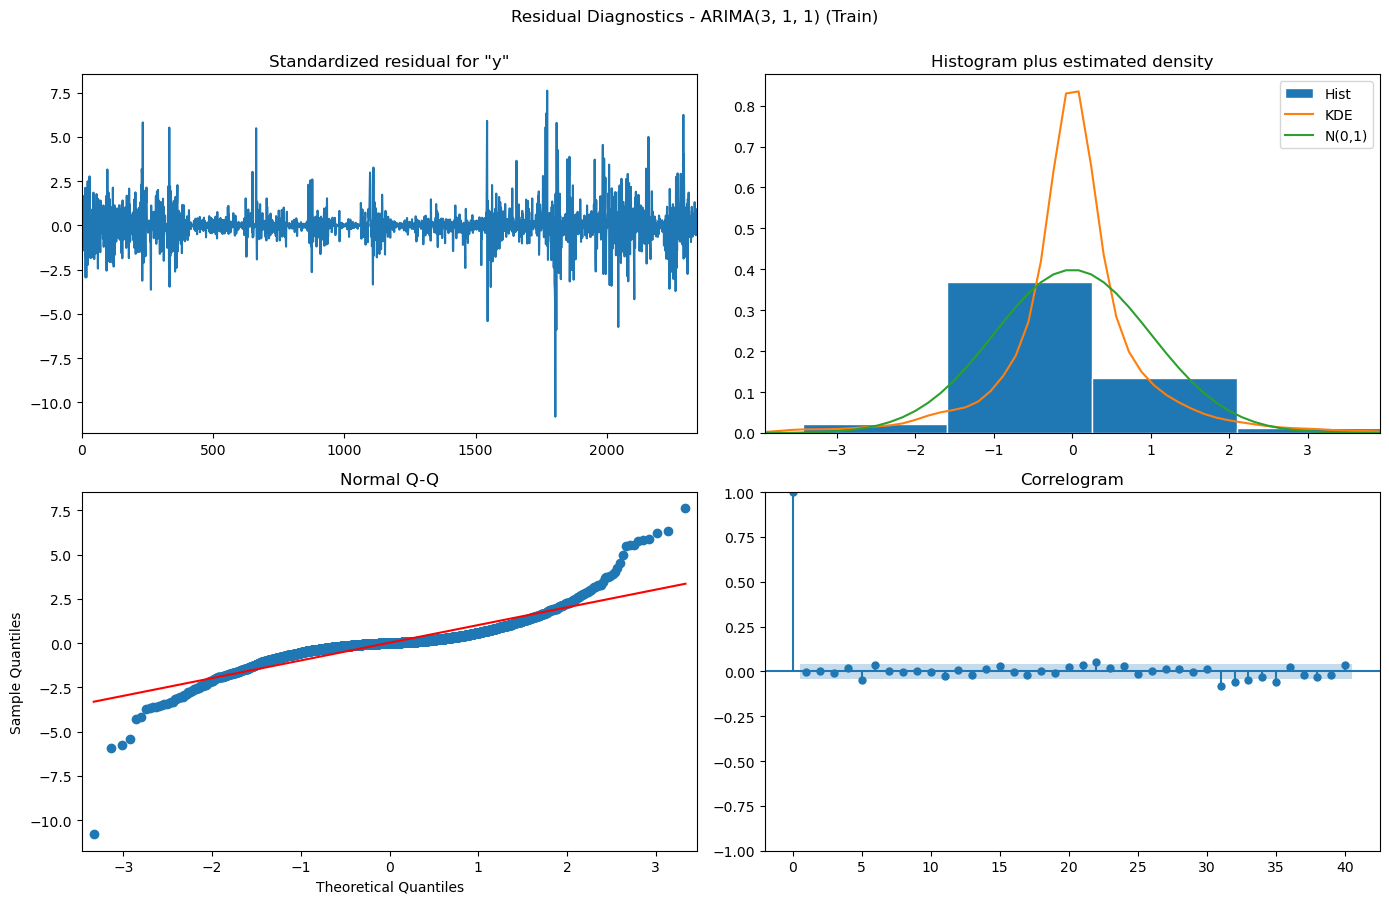

In [14]:
# ============================================================
# 10. CHẨN ĐOÁN PHẦN DƯ MÔ HÌNH CUỐI TRÊN TRAIN (HÌNH)
# ============================================================
# Bảng kiểm định (Ljung-Box trừ bậc tự do, ARCH-LM, Jarque-Bera) ở mục 12

fig = res_final_train.plot_diagnostics(figsize=(14, 9), lags=40)

fig.suptitle(f"Residual Diagnostics - ARIMA{final_order} (Train)", y=1.0)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "11_arima_residual_diagnostics_final.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Đánh giá mô hình

- **Quy đổi về giá theo kỳ vọng log-normal** (giống State Space): $\hat P_t = \exp\left(m_t/100 + v_t/(2\cdot 100^2)\right)$, với $m_t, v_t$ là trung bình và phương sai dự báo của $y_t = 100\ln P_t$. Naive giữ đúng $\hat P_t = P_{t-1}$.
- **MASE**: mẫu số là MAE của naive trên mẫu ước lượng (Train khi đánh giá Validation, Train + Validation khi đánh giá Test).
- **Đúng chiều (DA)**: tính trên mọi phiên và trên các phiên giá thực tế thay đổi; kiểm định nhị thức H₀: tỷ lệ đúng chiều = 50% trên các phiên có thay đổi.
- **Kiểm định chênh lệch loss**: $d_t = L(\text{mô hình}) - L(\text{naive})$ với loss bình phương và tuyệt đối; sai số chuẩn HAC Newey–West 5 độ trễ.
- **Bootstrap khối vòng ghép cặp**: 2.000 lần, khối dài 5, seed 20261010, cho ΔRMSE, ΔMAE và ΔMSE.
- **Ljung–Box phần dư có trừ bậc tự do** $p + q$.
- **Dự báo nhiều bước từ mốc cố định** cuối năm 2025, tầm 1, 5, 20, 60, 175 phiên.

In [15]:
# ============================================================
# 11.1 DỰ BÁO MỘT BƯỚC VÀ CHỈ SỐ THEO GIAO THỨC NHÓM
# ============================================================

P = price_all["Close"].values
n_tv = n_train + n_val

eval_orders = list(dict.fromkeys([
    (0, 1, 0),
    (1, 1, 1),
    (int(best_bic["p"]), 1, int(best_bic["q"])),
    final_order,
    aic_order
]))

segments_g = {
    "Validation": (n_train, n_train, n_tv),
    "Test": (n_tv, n_tv, len(y_all))
}

fits_g = {}

for seg, (fit_end, start, end) in segments_g.items():
    for order in eval_orders:
        fits_g[(seg, order)] = ARIMA(y_all[:fit_end], order=order, trend="n").fit()


def predict_price(res, start, end):

    pred = res.apply(y_all[:end]).get_prediction(start=start, end=end - 1)

    m = np.asarray(pred.predicted_mean)
    v = np.asarray(pred.var_pred_mean)
    ci = np.asarray(pred.conf_int(alpha=0.05))

    return {
        "mean": np.exp(m / 100 + v / (2 * 100 ** 2)),
        "median": np.exp(m / 100),
        "lower": np.exp(ci[:, 0] / 100),
        "upper": np.exp(ci[:, 1] / 100),
        "e_log": y_all[start:end] - m
    }


def hac_test(d, lags=5):
    """DM-type test: H0 E(d)=0, sai số chuẩn Newey-West (Bartlett) với `lags` độ trễ."""

    d = np.asarray(d, dtype=float)
    n = len(d)
    u = d - d.mean()

    s = np.sum(u * u) / n

    for k in range(1, lags + 1):
        s += 2 * (1 - k / (lags + 1)) * np.sum(u[k:] * u[:-k]) / n

    z = d.mean() / np.sqrt(s / n)

    return z, 2 * stats.norm.sf(abs(z))


def block_bootstrap(e_model, e_naive, n_boot=2000, block=5, seed=20261010):
    """Bootstrap khối vòng ghép cặp: CI 95% cho ΔRMSE, ΔMAE, ΔMSE (mô hình − naive)."""

    rng = np.random.default_rng(seed)

    n = len(e_model)
    n_blocks = int(np.ceil(n / block))

    out = np.empty((n_boot, 3))

    for b in range(n_boot):

        starts = rng.integers(0, n, n_blocks)
        idx = ((starts[:, None] + np.arange(block)) % n).ravel()[:n]

        a, c = e_model[idx], e_naive[idx]

        out[b] = [
            np.sqrt(np.mean(a ** 2)) - np.sqrt(np.mean(c ** 2)),
            np.mean(np.abs(a)) - np.mean(np.abs(c)),
            np.mean(a ** 2 - c ** 2)
        ]

    return np.percentile(out, [2.5, 97.5], axis=0)


def interval_score(y, lo, hi, alpha=0.05):
    return np.mean((hi - lo) + (2 / alpha) * (lo - y) * (y < lo) + (2 / alpha) * (y - hi) * (y > hi))


metric_rows = []
loss_rows = []
test_preds = {}

for seg, (fit_end, start, end) in segments_g.items():

    act = P[start:end]
    prev = P[start - 1:end - 1]

    e_naive = act - prev
    scale = np.mean(np.abs(np.diff(P[:fit_end])))
    changed = act != prev
    majority = max(np.sum(act > prev), np.sum(act < prev)) / changed.sum()

    for order in eval_orders:

        res = fits_g[(seg, order)]
        pr = predict_price(res, start, end)

        is_naive = order == (0, 1, 0)

        f = prev.copy() if is_naive else pr["mean"]
        e = act - f

        if seg == "Test":
            test_preds[order] = {**pr, "point": f}

        same_dir = np.sign(f - prev) == np.sign(act - prev)

        metric_rows.append({
            "Set": seg,
            "Model": f"ARIMA{order}" + (" = Naive" if is_naive else ""),
            "N": end - start,
            "MAE": np.mean(np.abs(e)),
            "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE (%)": 100 * np.mean(np.abs(e / act)),
            "sMAPE (%)": 100 * np.mean(2 * np.abs(e) / (np.abs(act) + np.abs(f))),
            "MASE": np.mean(np.abs(e)) / scale,
            "Relative RMSE": np.sqrt(np.mean(e ** 2)) / np.sqrt(np.mean(e_naive ** 2)),
            "DA all (%)": 100 * np.mean(same_dir),
            "DA changed (%)": 100 * np.mean(same_dir[changed]),
            "DA changed binom p": np.nan if is_naive else stats.binomtest(int(same_dir[changed].sum()), int(changed.sum()), 0.5).pvalue,
            # Mốc "luôn đoán theo chiều chiếm đa số" trong chính tập đánh giá: DA phải vượt mốc này mới có ý nghĩa
            "DA majority baseline (%)": 100 * majority,
            "DA vs majority p (one-sided)": np.nan if is_naive else stats.binomtest(int(same_dir[changed].sum()), int(changed.sum()), majority, alternative="greater").pvalue,
            "Coverage 95% (%)": 100 * np.mean((act >= pr["lower"]) & (act <= pr["upper"])),
            "Width 95%": np.mean(pr["upper"] - pr["lower"]),
            "Interval score": interval_score(act, pr["lower"], pr["upper"]),
            "Mean - median (VND)": np.mean(pr["mean"] - pr["median"]),
            "MASE scale": scale
        })

        if is_naive:
            continue

        z_sq, p_sq = hac_test(e ** 2 - e_naive ** 2)
        z_ab, p_ab = hac_test(np.abs(e) - np.abs(e_naive))
        ci = block_bootstrap(e, e_naive)

        loss_rows.append({
            "Set": seg,
            "Model": f"ARIMA{order}",
            "Mean ΔMSE": np.mean(e ** 2 - e_naive ** 2),
            "HAC z (squared)": z_sq,
            "HAC p (squared)": p_sq,
            "Mean ΔMAE": np.mean(np.abs(e) - np.abs(e_naive)),
            "HAC z (absolute)": z_ab,
            "HAC p (absolute)": p_ab,
            "ΔRMSE": np.sqrt(np.mean(e ** 2)) - np.sqrt(np.mean(e_naive ** 2)),
            "ΔRMSE CI low": ci[0, 0],
            "ΔRMSE CI high": ci[1, 0],
            "ΔMAE CI low": ci[0, 1],
            "ΔMAE CI high": ci[1, 1],
            "ΔMSE CI low": ci[0, 2],
            "ΔMSE CI high": ci[1, 2]
        })

metrics_g = pd.DataFrame(metric_rows)
loss_g = pd.DataFrame(loss_rows)

metrics_g.to_csv(RESULT_DIR / "arima_metrics_group_protocol.csv", index=False)
loss_g.to_csv(RESULT_DIR / "arima_loss_tests_hac_bootstrap.csv", index=False)

pd.set_option("display.width", 250)

print(metrics_g.round(6).to_string(index=False))
print()
print(loss_g.round(6).to_string(index=False))

       Set                  Model   N       MAE      RMSE  MAPE (%)  sMAPE (%)     MASE  Relative RMSE  DA all (%)  DA changed (%)  DA changed binom p  DA majority baseline (%)  DA vs majority p (one-sided)  Coverage 95% (%)  Width 95%  Interval score  Mean - median (VND)  MASE scale
Validation ARIMA(0, 1, 0) = Naive 262 25.187023 43.252829  0.097463   0.097492 1.439890       1.000000    8.396947        0.000000                 NaN                 51.666667                           NaN         92.366412 136.694128      310.607368             0.023385   17.492327
Validation         ARIMA(1, 1, 1) 262 25.432885 43.172578  0.098428   0.098455 1.453945       0.998145   48.091603       52.500000            0.477752                 51.666667                      0.423480         92.748092 135.668175      311.165334             0.023035   17.492327
Validation         ARIMA(3, 1, 1) 262 25.948813 43.125272  0.100446   0.100461 1.483440       0.997051   41.603053       45.416667            0.1

      Date   Close  Forecast  Lower 95%  Upper 95%   Error  Naive forecast  Naive error
2026-01-01 26300.0 26302.263  26232.585  26372.078  -2.263         26300.0          0.0
2026-01-02 26300.0 26294.318  26224.660  26364.111   5.682         26300.0          0.0
2026-01-05 26274.5 26302.576  26232.897  26372.392 -28.076         26300.0        -25.5
2026-01-06 26275.5 26273.814  26204.211  26343.554   1.686         26274.5          1.0
2026-01-07 26274.0 26277.888  26208.274  26347.638  -3.888         26275.5         -1.5


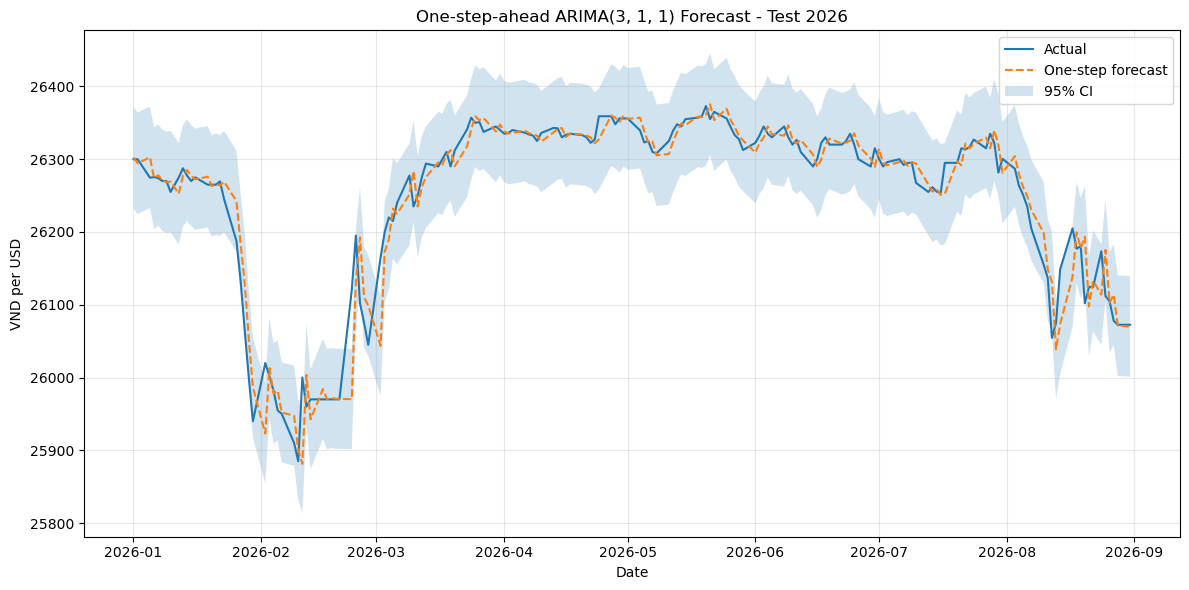

In [16]:
# ============================================================
# 11.2 DỰ BÁO TỪNG PHIÊN TRÊN TEST VÀ ĐỒ THỊ
# ============================================================
# Xuất actual, prediction, error theo từng ngày (theo giao thức chung của nhóm)

pr = test_preds[final_order]

act_test = P[n_tv:]
prev_test = P[n_tv - 1:-1]

test_output = pd.DataFrame({
    "Date": price_test["Date"].values,
    "Close": act_test,
    "Forecast": pr["point"],
    "Lower 95%": pr["lower"],
    "Upper 95%": pr["upper"],
    "Error": act_test - pr["point"],
    "Naive forecast": prev_test,
    "Naive error": act_test - prev_test
})

test_output.to_csv(RESULT_DIR / "arima_test_forecasts.csv", index=False)

print(test_output.head().round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(price_test["Date"], act_test, label="Actual")
ax.plot(price_test["Date"], pr["point"], linestyle="--", label="One-step forecast")
ax.fill_between(price_test["Date"], pr["lower"], pr["upper"], alpha=0.2, label="95% CI")

ax.set_title(f"One-step-ahead ARIMA{final_order} Forecast - Test 2026")
ax.set_xlabel("Date")
ax.set_ylabel("VND per USD")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "15_arima_onestep_test.png", dpi=300)
plt.show()

In [17]:
# ============================================================
# 12. ƯỚC LƯỢNG LẠI VÀ CHẨN ĐOÁN PHẦN DƯ (LJUNG-BOX TRỪ BẬC TỰ DO)
# ============================================================

diag_rows = []
refit_rows = []

for seg, sample in [("Validation", "Train"), ("Test", "Train + Validation")]:

    for order in eval_orders:

        res = fits_g[(seg, order)]
        k = order[0] + order[2]

        refit_rows.append({
            "Sample": sample,
            "Model": f"ARIMA{order}",
            "N": res.nobs,
            "Log-likelihood": res.llf,
            "AIC": res.aic,
            "BIC": res.bic,
            "sigma2": res.params[-1],
            "Converged": res.mle_retvals.get("converged", True) if res.mle_retvals else True,
            "Min |AR root|": np.abs(res.arroots).min() if order[0] else np.nan,
            "Min |MA root|": np.abs(res.maroots).min() if order[2] else np.nan
        })

        resid = res.resid[1:]

        row = {"Sample": sample, "Model": f"ARIMA{order}", "p + q": k}

        for lag in [5, 10, 20]:
            row[f"LB({lag}) df"] = lag - k
            if lag > k:
                row[f"LB({lag}) p"] = acorr_ljungbox(resid, lags=[lag], model_df=k)["lb_pvalue"].iloc[0]
            else:
                row[f"LB({lag}) p"] = np.nan

        row["LB resid² (10) p"] = acorr_ljungbox(resid ** 2, lags=[10])["lb_pvalue"].iloc[0]
        row["ARCH-LM(10) p"] = het_arch(resid, nlags=10)[1]
        row["Jarque-Bera p"] = jarque_bera(resid)[1]
        row["Kurtosis"] = stats.kurtosis(resid, fisher=False)

        diag_rows.append(row)

refit_g = pd.DataFrame(refit_rows)
diag_g = pd.DataFrame(diag_rows)

# Sai số dự báo trên Test (thang log): không trừ bậc tự do vì không phải phần dư ước lượng
test_err_rows = []

for order, pr in test_preds.items():

    e = pr["e_log"]

    test_err_rows.append({
        "Model": f"ARIMA{order}",
        "LB(5) p": acorr_ljungbox(e, lags=[5])["lb_pvalue"].iloc[0],
        "LB(10) p": acorr_ljungbox(e, lags=[10])["lb_pvalue"].iloc[0],
        "LB(20) p": acorr_ljungbox(e, lags=[20])["lb_pvalue"].iloc[0],
        "ARCH-LM(10) p": het_arch(e, nlags=10)[1],
        "Jarque-Bera p": jarque_bera(e)[1],
        "Kurtosis": stats.kurtosis(e, fisher=False)
    })

test_err_g = pd.DataFrame(test_err_rows)

refit_g.to_csv(RESULT_DIR / "arima_refit_summary.csv", index=False)
diag_g.to_csv(RESULT_DIR / "arima_residual_tests_df_adjusted.csv", index=False)
test_err_g.to_csv(RESULT_DIR / "arima_test_error_diagnostics.csv", index=False)

print(refit_g.round(4).to_string(index=False))
print()
print(diag_g.round(6).to_string(index=False))
print()
print(test_err_g.round(6).to_string(index=False))

            Sample          Model    N  Log-likelihood        AIC        BIC  sigma2  Converged  Min |AR root|  Min |MA root|
             Train ARIMA(0, 1, 0) 2347       1384.2847 -2766.5694 -2760.8089  0.0180       True            NaN            NaN
             Train ARIMA(1, 1, 1) 2347       1401.9375 -2797.8750 -2780.5936  0.0177       True         2.9094         2.1770
             Train ARIMA(3, 1, 1) 2347       1436.2759 -2862.5518 -2833.7495  0.0172       True         1.2599         1.7574
             Train ARIMA(3, 1, 4) 2347       1441.1142 -2866.2283 -2820.1446  0.0171       True         1.2159         1.3621
Train + Validation ARIMA(0, 1, 0) 2609       1465.0303 -2928.0607 -2922.1943  0.0190       True            NaN            NaN
Train + Validation ARIMA(1, 1, 1) 2609       1482.7491 -2959.4981 -2941.8991  0.0188       True         2.3794         1.8996
Train + Validation ARIMA(3, 1, 1) 2609       1516.0341 -3022.0681 -2992.7364  0.0183       True         1.2858        

In [18]:
# ============================================================
# 13. DỰ BÁO NHIỀU BƯỚC TỪ MỐC CỐ ĐỊNH (CUỐI 2025)
# ============================================================
# Tham số ước lượng trên Train + Validation, dự báo liên tục 175 phiên Test
# mà không cập nhật bằng giá thực tế (khác với rolling one-step)

act_test = P[n_tv:]
horizons = [1, 5, 20, 60, n_test]

fixed_rows = []
fixed_paths = {}

for order in eval_orders:

    fc = fits_g[("Test", order)].get_forecast(steps=n_test)

    m = np.asarray(fc.predicted_mean)
    v = np.asarray(fc.var_pred_mean)
    ci = np.asarray(fc.conf_int(alpha=0.05))

    point = np.full(n_test, P[n_tv - 1]) if order == (0, 1, 0) else np.exp(m / 100 + v / (2 * 100 ** 2))
    lo = np.exp(ci[:, 0] / 100)
    hi = np.exp(ci[:, 1] / 100)

    fixed_paths[order] = (point, lo, hi)

    for h in horizons:

        e = act_test[:h] - point[:h]

        fixed_rows.append({
            "Model": f"ARIMA{order}",
            "Horizon": h,
            "MAE": np.mean(np.abs(e)),
            "RMSE": np.sqrt(np.mean(e ** 2)),
            "Mean PI width": np.mean(hi[:h] - lo[:h]),
            "Coverage (%)": 100 * np.mean((act_test[:h] >= lo[:h]) & (act_test[:h] <= hi[:h]))
        })

fixed_g = pd.DataFrame(fixed_rows)

fixed_g.to_csv(RESULT_DIR / "arima_fixed_origin_multistep.csv", index=False)

print(fixed_g.round(2).to_string(index=False))

         Model  Horizon    MAE   RMSE  Mean PI width  Coverage (%)
ARIMA(0, 1, 0)        1   0.00   0.00         142.24        100.00
ARIMA(0, 1, 0)        5  15.20  19.63         238.46        100.00
ARIMA(0, 1, 0)       20  38.25  53.11         438.58        100.00
ARIMA(0, 1, 0)       60 140.12 195.00         743.26         95.00
ARIMA(0, 1, 0)      175  82.95 130.41        1259.81         98.29
ARIMA(1, 1, 1)        1   4.18   4.18         141.30        100.00
ARIMA(1, 1, 1)        5  18.38  22.13         249.46        100.00
ARIMA(1, 1, 1)       20  41.51  55.55         465.41        100.00
ARIMA(1, 1, 1)       60 143.32 197.66         791.80         96.67
ARIMA(1, 1, 1)      175  83.37 132.43        1343.95         98.86
ARIMA(3, 1, 1)        1   2.26   2.26         139.49        100.00
ARIMA(3, 1, 1)        5  16.52  20.01         248.03        100.00
ARIMA(3, 1, 1)       20  41.12  55.56         538.75        100.00
ARIMA(3, 1, 1)       60 143.82 198.36        1006.73        10

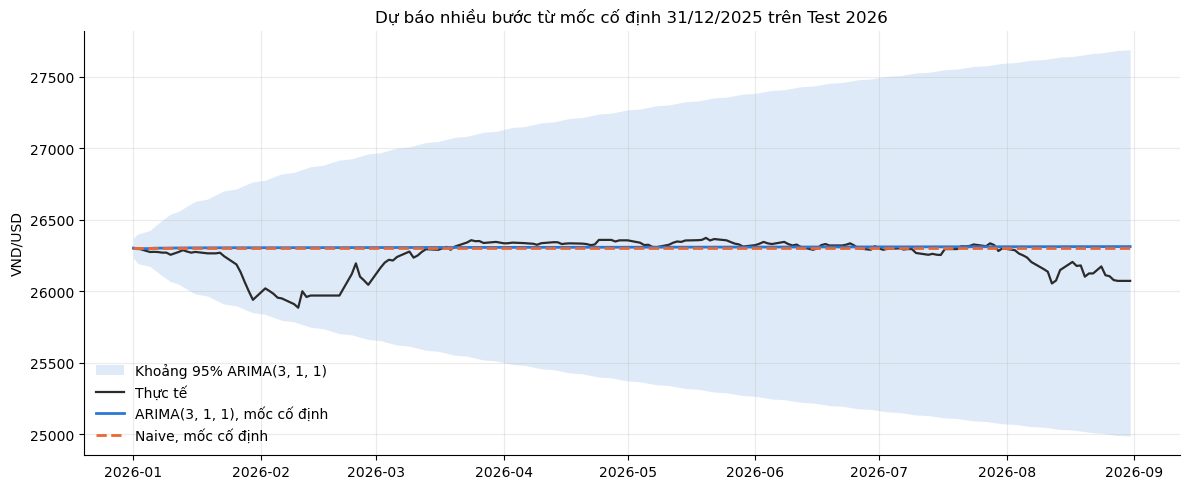

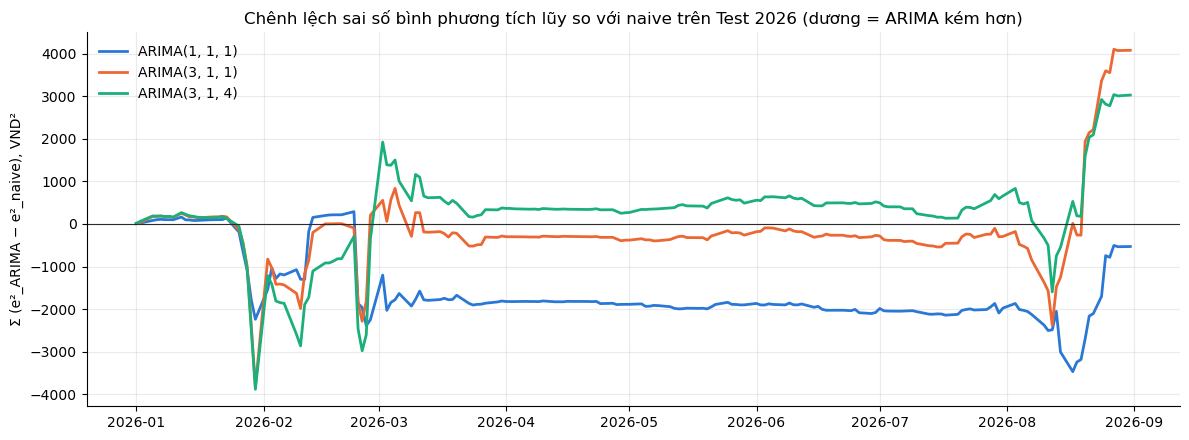

In [19]:
# ============================================================
# 14. HÌNH: DỰ BÁO MỐC CỐ ĐỊNH VÀ CHÊNH LỆCH LOSS TÍCH LŨY
# ============================================================

INK = "#2b2b2b"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]

test_dates = price_all["Date"].iloc[n_tv:].values

fig, ax = plt.subplots(figsize=(12, 5))

point, lo, hi = fixed_paths[final_order]

ax.fill_between(test_dates, lo, hi, color=SERIES[0], alpha=0.15, linewidth=0, label=f"Khoảng 95% ARIMA{final_order}")
ax.plot(test_dates, act_test, color=INK, linewidth=1.6, label="Thực tế")
ax.plot(test_dates, point, color=SERIES[0], linewidth=2, label=f"ARIMA{final_order}, mốc cố định")
ax.plot(test_dates, fixed_paths[(0, 1, 0)][0], color=SERIES[1], linewidth=2, linestyle="--", label="Naive, mốc cố định")

ax.set_title("Dự báo nhiều bước từ mốc cố định 31/12/2025 trên Test 2026")
ax.set_ylabel("VND/USD")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left", frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "20_arima_fixed_origin_test.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))

e_naive_test = act_test - P[n_tv - 1:-1]

for color, order in zip(SERIES, [o for o in eval_orders if o != (0, 1, 0)]):

    e = act_test - test_preds[order]["point"]
    ax.plot(test_dates, np.cumsum(e ** 2 - e_naive_test ** 2), color=color, linewidth=2, label=f"ARIMA{order}")

ax.axhline(0, color=INK, linewidth=0.8)
ax.set_title("Chênh lệch sai số bình phương tích lũy so với naive trên Test 2026 (dương = ARIMA kém hơn)")
ax.set_ylabel("Σ (e²_ARIMA − e²_naive), VND²")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "21_arima_cumulative_loss_diff_test.png", dpi=300)
plt.show()

In [20]:
# ============================================================
# 15. KIỂM TRA ĐỘ VỮNG (ROBUSTNESS)
# ============================================================
# Kiểm tra kết quả so với Naive có thay đổi khi đổi cách ước lượng, xử lý ngoại lai hoặc dữ liệu hay không
# Làm việc trên sai phân log-price (= log-return %), tương đương ARIMA(p,1,q) trên log_price

x_all = np.diff(y_all)

segments = {
    "Validation": (n_train - 1, n_train + n_val - 1),
    "Test": (n_train + n_val - 1, len(x_all))
}

def rmse(e):
    return np.sqrt(np.mean(e ** 2))

In [21]:
# ------------------------------------------------------------
# 15.1 ƯỚC LƯỢNG LẠI CUỐN CHIẾU (ROLLING / EXPANDING WINDOW)
# ------------------------------------------------------------
# Ước lượng lại tham số mỗi 20 phiên trên cửa sổ dài W ngày gần nhất
# (W = None: dùng toàn bộ lịch sử - expanding window), dự báo 1 bước mỗi ngày

REFIT_EVERY = 20

def rolling_forecast(x, order, start, end, window):

    preds = []

    for t in range(start, end):

        if (t - start) % REFIT_EVERY == 0:

            lo = 0 if window is None else t - window

            res = ARIMA(x[lo:t], order=order, trend="n").fit()

        # áp tham số hiện tại cho dữ liệu đến t-1, lấy dự báo cho t
        res_t = res.apply(x[lo:t + 1])

        preds.append(res_t.forecasts[0, -1])

    return np.array(preds)


rolling_rows = []

for seg_name, (a, b) in segments.items():

    rmse_rw = rmse(x_all[a:b])

    for order in dict.fromkeys([(1, 0, 0), (0, 0, 1), final_order[:1] + (0,) + final_order[2:], aic_order[:1] + (0,) + aic_order[2:]]):

        for window in [250, 500, 1000, None]:

            pred = rolling_forecast(x_all, order, a, b, window)

            e = x_all[a:b] - pred

            rolling_rows.append({
                "Segment": seg_name,
                "Model": f"ARIMA({order[0]},1,{order[2]})",
                "Window": "Expanding" if window is None else window,
                "RMSE return (%)": rmse(e),
                "Theil U (vs RW)": rmse(e) / rmse_rw
            })

rolling_table = pd.DataFrame(rolling_rows)

rolling_table.to_csv(
    RESULT_DIR / "arima_robustness_rolling.csv",
    index=False
)

print(
    rolling_table
    .pivot_table(index=["Model", "Window"], columns="Segment", values="Theil U (vs RW)", sort=False)
    .round(4)
)

Segment                 Validation    Test
Model        Window                       
ARIMA(1,1,0) 250            1.0133  1.0044
             500            1.0122  0.9954
             1000           1.0202  0.9976
             Expanding      1.0068  0.9954
ARIMA(0,1,1) 250            1.0095  1.0081
             500            1.0119  0.9945
             1000           1.0147  0.9975
             Expanding      1.0055  0.9949
ARIMA(3,1,1) 250            1.0045  1.0142
             500            1.0037  1.0222
             1000           1.0074  1.0156
             Expanding      0.9962  1.0122
ARIMA(3,1,4) 250            1.0090  1.0792
             500            1.0041  1.0204
             1000           1.0110  1.0112
             Expanding      0.9926  1.0094


In [22]:
# ------------------------------------------------------------
# 15.2 XỬ LÝ NGOẠI LAI BẰNG BIẾN GIẢ (Cryer & Chan - outliers)
# ------------------------------------------------------------
# Các ngày có |z| > 4 được gán 1 biến giả riêng (additive outlier)
# Câu hỏi: tự tương quan nhỏ còn lại có phải do vài ngày cực đoan gây ra?

x_train = x_all[:n_train - 1]

z = (x_train - x_train.mean()) / x_train.std()

outlier_idx = np.where(np.abs(z) > 4)[0]

dummies = np.zeros((len(x_train), len(outlier_idx)))
dummies[outlier_idx, np.arange(len(outlier_idx))] = 1

print("Số ngày ngoại lai |z| > 4:", len(outlier_idx))
print(price_all["Date"].iloc[outlier_idx + 1].dt.strftime("%Y-%m-%d").tolist())

outlier_rows = []

for order in [(1, 0, 0), (0, 0, 1)]:

    for use_dummy in [False, True]:

        res = ARIMA(
            x_train,
            order=order,
            trend="n",
            exog=dummies if use_dummy else None
        ).fit()

        name = "ar.L1" if order[0] == 1 else "ma.L1"
        k = res.param_names.index(name)

        outlier_rows.append({
            "Model": f"ARIMA({order[0]},1,{order[2]})",
            "Outlier dummies": use_dummy,
            "Parameter": name,
            "Estimate": res.params[k],
            "p-value": res.pvalues[k],
            "Ljung-Box(10) p": acorr_ljungbox(res.resid, lags=[10])["lb_pvalue"].iloc[0],
            "Ljung-Box(20) p": acorr_ljungbox(res.resid, lags=[20])["lb_pvalue"].iloc[0]
        })

outlier_table = pd.DataFrame(outlier_rows)

outlier_table.to_csv(
    RESULT_DIR / "arima_robustness_outliers.csv",
    index=False
)

print(outlier_table.round(4).to_string(index=False))

Số ngày ngoại lai |z| > 4: 18
['2016-11-24', '2017-04-14', '2018-07-23', '2021-12-06', '2021-12-08', '2022-10-13', '2022-10-17', '2022-10-21', '2022-12-02', '2022-12-05', '2022-12-09', '2022-12-12', '2023-02-17', '2023-08-15', '2023-11-06', '2024-01-30', '2024-04-15', '2024-10-17']
       Model  Outlier dummies Parameter  Estimate  p-value  Ljung-Box(10) p  Ljung-Box(20) p
ARIMA(1,1,0)            False     ar.L1    0.1088      0.0              0.0              0.0
ARIMA(1,1,0)             True     ar.L1    0.0712      0.0              0.0              0.0
ARIMA(0,1,1)            False     ma.L1    0.1167      0.0              0.0              0.0
ARIMA(0,1,1)             True     ma.L1    0.0904      0.0              0.0              0.0


In [23]:
# ------------------------------------------------------------
# 15.3 HIỆU ỨNG NGÀY TRONG TUẦN (có cần SARIMA chu kỳ 5?)
# ------------------------------------------------------------

weekday = price_all["Date"].iloc[1:n_train].dt.dayofweek.values

weekday_table = (
    pd.DataFrame({"Weekday": weekday, "Return": x_train})
    .groupby("Weekday")["Return"]
    .agg(["mean", "std", "count"])
)

weekday_table.index = [["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][d] for d in weekday_table.index]

print(weekday_table.round(4))

anova = stats.f_oneway(*[x_train[weekday == d] for d in range(5) if (weekday == d).sum() > 1])

print("\nANOVA: F =", round(anova.statistic, 4), "| p-value =", round(anova.pvalue, 4))

       mean     std  count
Mon  0.0134  0.1638    469
Tue  0.0156  0.1155    470
Wed  0.0063  0.1186    469
Thu -0.0038  0.1279    469
Fri -0.0043  0.1380    469

ANOVA: F = 2.2748 | p-value = 0.059


In [24]:
# ------------------------------------------------------------
# 15.4 KHOẢNG DỰ BÁO CỦA NAIVE: PHƯƠNG SAI HẰNG vs PHƯƠNG SAI CUỐN CHIẾU
# ------------------------------------------------------------
# ARIMA(0,1,0): dự báo return = 0, khoảng 95% = ±1.96 * sigma
# - Hằng: sigma ước lượng từ toàn bộ dữ liệu trước giai đoạn dự báo
# - Cuốn chiếu: sigma = độ lệch chuẩn 60 phiên gần nhất (chỉ dùng thông tin quá khứ)

ROLL = 60

coverage_rows = []

for seg_name, (a, b) in segments.items():

    actual = x_all[a:b]

    sigma_const = np.full(b - a, x_all[:a].std())
    sigma_roll = np.array([x_all[t - ROLL:t].std() for t in range(a, b)])

    for name, sigma in [("Constant", sigma_const), (f"Rolling {ROLL}d", sigma_roll)]:

        coverage_rows.append({
            "Segment": seg_name,
            "Sigma": name,
            "95% coverage": np.mean(np.abs(actual) <= 1.96 * sigma),
            "Mean band width (%)": np.mean(2 * 1.96 * sigma)
        })

coverage_table = pd.DataFrame(coverage_rows)

coverage_table.to_csv(
    RESULT_DIR / "arima_robustness_coverage.csv",
    index=False
)

print(coverage_table.round(4).to_string(index=False))

   Segment       Sigma  95% coverage  Mean band width (%)
Validation    Constant        0.9237               0.5253
Validation Rolling 60d        0.9275               0.6039
      Test    Constant        0.9486               0.5403
      Test Rolling 60d        0.8686               0.3715



===== TRAIN =====
Model                       ARIMA(0, 1, 0) ARIMA(1, 1, 1) ARIMA(3, 1, 1) ARIMA(3, 1, 4)
N                                     2346           2346           2346           2346
MAE                              17.492327      17.621259      17.688820      17.699644
RMSE                             31.771224      31.500781      31.032764      30.969938
MAPE (%)                          0.074512       0.075098       0.075371       0.075423
sMAPE (%)                         0.074520       0.075106       0.075377       0.075429
MASE (train naive scale)          1.000000       1.007371       1.011233       1.011852
MASE (same-set naive scale)       1.000000       1.007371       1.011233       1.011852
Directional Accuracy (%)               NaN      42.924126      43.947144      43.648764
Relative RMSE vs Naive            1.000000       0.991488       0.976757       0.974779
DM p-value vs Naive                    NaN       0.069998       0.053393       0.059144
95% PI Covera

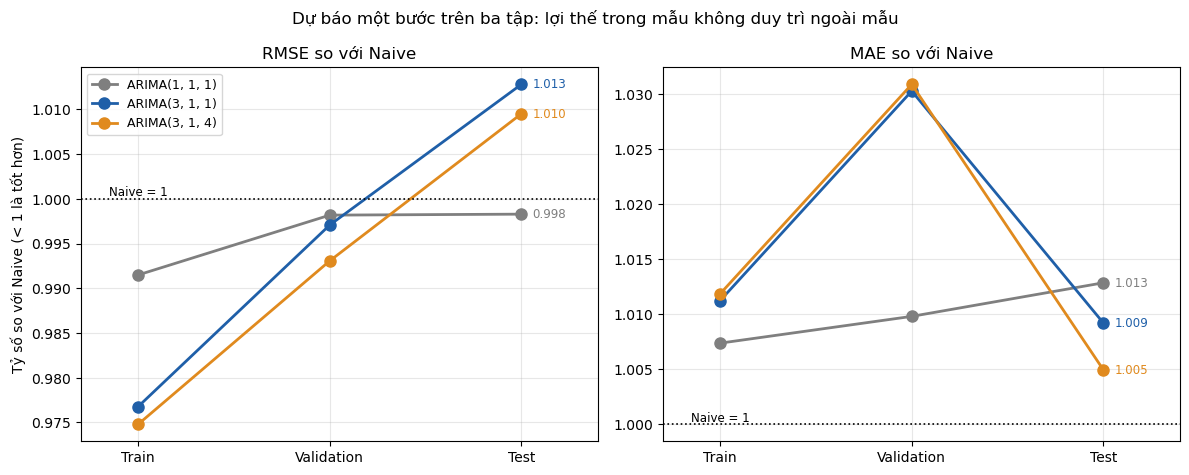

In [25]:
# ============================================================
# 15.5 BẢNG CHỈ SỐ THEO ĐỊNH DẠNG STATE SPACE: TRAIN / VALIDATION / TEST
# ============================================================
# Bảng chỉ số chung của nhóm cho ba tập, tính trên giá (VND), dự báo 1 bước, quy đổi giá theo trung vị exp(m/100):
# - Train     : tham số ước lượng trên train, dự báo 1 bước trong mẫu (bỏ quan sát đầu)
# - Validation: tham số ước lượng trên train, lọc qua train + validation
# - Test      : tham số ước lượng trên train + validation, lọc qua toàn bộ chuỗi
# Cột 'MASE (train naive scale)' dùng mẫu số là MAE naive trên Train cho cả ba tập,
# khác MASE ở mục 11.1 (mẫu số là MAE naive trên mẫu ước lượng); báo cáo dùng MASE của mục 11.1.
# Bảng này cung cấp Hình 23 và so sánh trong mẫu trên Train.

price_close = price_all["Close"].values

scale_train = np.mean(np.abs(np.diff(price_close[:n_train])))

eval_segments = {
    "Train": (y_train, y_train, 1, n_train),
    "Validation": (y_train, y_train_val, n_train, n_train + n_val),
    "Test": (y_train_val, y_all, n_train + n_val, len(y_all))
}

models = {f"ARIMA{o}": o for o in dict.fromkeys([(0, 1, 0), (1, 1, 1), (int(best_bic["p"]), 1, int(best_bic["q"])), final_order, aic_order])}


def fit_model(spec, fit_series):

    return ARIMA(fit_series, order=spec, trend="n").fit()


def segment_metrics(res, fit_series, full_series, start, end):

    res_full = res if len(full_series) == len(fit_series) else res.apply(full_series)

    pred = res_full.get_prediction(start=start, end=end - 1)

    m = pred.predicted_mean
    ci = pred.conf_int(alpha=0.05)

    f = np.exp(m / 100)
    lo = np.exp(ci[:, 0] / 100)
    hi = np.exp(ci[:, 1] / 100)

    act = price_close[start:end]
    prev = price_close[start - 1:end - 1]

    e = act - f
    e_rw = act - prev
    e_log = full_series[start:end] - m

    is_rw = np.allclose(f, prev)

    # DM với sai số chuẩn HAC Newey-West 5 độ trễ (cùng hàm hac_test ở mục 11.1)
    dm_p = np.nan if is_rw else hac_test(e ** 2 - e_rw ** 2)[1]

    return {
        "N": end - start,
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e ** 2)),
        "MAPE (%)": 100 * np.mean(np.abs(e / act)),
        "sMAPE (%)": 100 * np.mean(2 * np.abs(e) / (np.abs(act) + np.abs(f))),
        "MASE (train naive scale)": np.mean(np.abs(e)) / scale_train,
        "MASE (same-set naive scale)": np.mean(np.abs(e)) / np.mean(np.abs(e_rw)),
        "Directional Accuracy (%)": np.nan if is_rw else 100 * np.mean(np.sign(f - prev) == np.sign(act - prev)),
        "Relative RMSE vs Naive": np.sqrt(np.mean(e ** 2)) / np.sqrt(np.mean(e_rw ** 2)),
        "DM p-value vs Naive": dm_p,
        "95% PI Coverage (%)": 100 * np.mean((act >= lo) & (act <= hi)),
        "Average 95% PI Width": np.mean(hi - lo),
        "Ljung-Box p lag 20": acorr_ljungbox(e_log, lags=[20])["lb_pvalue"].iloc[0],
        "Jarque-Bera p": jarque_bera(e_log)[1],
        "ARCH-LM p": het_arch(e_log, nlags=10)[1],
        "Optimizer converged": res.mle_retvals.get("converged", True) if res.mle_retvals else True
    }


all_rows = []
fitted = {}

for seg_name, (fit_series, full_series, start, end) in eval_segments.items():

    for name, spec in models.items():

        key = (name, len(fit_series))

        if key not in fitted:
            fitted[key] = fit_model(spec, fit_series)

        row = segment_metrics(fitted[key], fit_series, full_series, start, end)
        row.update({"Set": seg_name, "Model": name})

        all_rows.append(row)

metrics_all = pd.DataFrame(all_rows).set_index(["Set", "Model"])

metrics_all.to_csv(RESULT_DIR / "arima_metrics_all_sets_ss_format.csv")

for seg_name in eval_segments:
    print(f"\n===== {seg_name.upper()} =====")
    print(metrics_all.loc[seg_name].T.to_string(float_format=lambda v: f"{v:.6f}"))

# ------------------------------------------------------------
# Hình 23: RMSE và MAE so với Naive trên ba tập
# ------------------------------------------------------------

sets = ["Train", "Validation", "Test"]
naive_name = "ARIMA(0, 1, 0)"
cmp_models = [m for m in metrics_all.loc["Train"].index if m.startswith("ARIMA") and m != naive_name]
colors = {"ARIMA(1, 1, 1)": "#7f7f7f", f"ARIMA{final_order}": "#1f5fa8", f"ARIMA{aic_order}": "#e08a1e"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)

for ax, metric, title in [(axes[0], "RMSE", "RMSE so với Naive"), (axes[1], "MAE", "MAE so với Naive")]:
    for m in cmp_models:
        vals = [metrics_all.loc[(s, m), metric] / metrics_all.loc[(s, naive_name), metric] for s in sets]
        ax.plot(sets, vals, marker="o", linewidth=2, markersize=8, color=colors.get(m, None), label=m)
        ax.annotate(f"{vals[-1]:.3f}", (2, vals[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=colors.get(m, None))
    ax.axhline(1, color="black", linestyle=":", linewidth=1.2)
    ax.text(-0.15, 1, "Naive = 1", va="bottom", fontsize=8.5)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.set_xlim(-0.3, 2.4)

axes[0].set_ylabel("Tỷ số so với Naive (< 1 là tốt hơn)")
axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("Dự báo một bước trên ba tập: lợi thế trong mẫu không duy trì ngoài mẫu")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "23_arima_relative_three_sets.png", dpi=300)
plt.show()

In [26]:
# ============================================================
# 15.6 ĐỘ VỮNG: BỎ CÁC NGÀY LỄ BỊ ĐIỀN GIÁ CŨ
# ============================================================
# Dữ liệu có 105 ngày (Tết, 30/4, 1/5, 2/9, 1/1) có Open = High = Low = Close
# và bằng giá ngày trước -> nguồn dữ liệu điền giá cũ cho ngày không giao dịch.
# Các ngày này tạo return = 0 giả và dồn biến động vào ngày mở cửa lại.
# Bỏ các ngày này, giữ nguyên mốc chia train / validation / test, rồi:
#   (a) chọn lại bậc theo AIC/BIC trên train
#   (b) so sánh dự báo 1 bước với naive trên validation và test

holiday = (
    (price_all["Open"] == price_all["High"])
    & (price_all["High"] == price_all["Low"])
    & (price_all["Low"] == price_all["Close"])
).values

print("Số ngày lễ bị điền giá cũ:", holiday.sum())

price_nh = price_all.loc[~holiday].reset_index(drop=True)
y_nh = price_nh["log_price"].values * 100

n_train_nh = int((price_nh["Date"] <= price_train["Date"].max()).sum())
n_tv_nh = int((price_nh["Date"] <= price_val["Date"].max()).sum())

print("Train:", n_train_nh, "| Validation:", n_tv_nh - n_train_nh, "| Test:", len(y_nh) - n_tv_nh)

x_nh = np.diff(y_nh[:n_train_nh])
print("Tỷ lệ return = 0 trên train: trước", round(100 * np.mean(x_all[:n_train - 1] == 0), 1),
      "% -> sau", round(100 * np.mean(x_nh == 0), 1), "%")

grid_nh = []

for p, q in itertools.product(range(5), range(5)):

    try:
        r = ARIMA(y_nh[:n_train_nh], order=(p, 1, q), trend="n").fit()
        grid_nh.append({"p": p, "q": q, "AIC": r.aic, "BIC": r.bic})
    except Exception:
        pass

grid_nh = pd.DataFrame(grid_nh)

aic_nh = grid_nh.loc[grid_nh["AIC"].idxmin()]
bic_nh = grid_nh.loc[grid_nh["BIC"].idxmin()]

print("AIC chọn:", (int(aic_nh.p), 1, int(aic_nh.q)), "| BIC chọn:", (int(bic_nh.p), 1, int(bic_nh.q)))

orders_nh = list(dict.fromkeys([
    (1, 1, 1),
    (int(bic_nh.p), 1, int(bic_nh.q)),
    (int(aic_nh.p), 1, int(aic_nh.q)),
    final_order
]))

holiday_rows = []

for seg, fit_end, start, end in [
    ("Validation", n_train_nh, n_train_nh, n_tv_nh),
    ("Test", n_tv_nh, n_tv_nh, len(y_nh))
]:

    act = y_nh[start:end]
    prev = y_nh[start - 1:end - 1]
    e_rw = act - prev

    for order in orders_nh:

        res = ARIMA(y_nh[:fit_end], order=order, trend="n").fit()
        f = res.apply(y_nh[:end]).get_prediction(start=start, end=end - 1).predicted_mean

        e = act - f
        # DM không HAC (giữ như kết quả đã báo cáo trong Bảng P1.10)
        dm, dm_p = diebold_mariano(e, e_rw)

        price_e = np.exp(act / 100) - np.exp(f / 100)
        price_e_rw = np.exp(act / 100) - np.exp(prev / 100)

        holiday_rows.append({
            "Set": seg,
            "Model": f"ARIMA{order}",
            "N": end - start,
            "RMSE price": np.sqrt(np.mean(price_e ** 2)),
            "RMSE naive": np.sqrt(np.mean(price_e_rw ** 2)),
            "MAE price": np.mean(np.abs(price_e)),
            "MAE naive": np.mean(np.abs(price_e_rw)),
            "Theil U": np.sqrt(np.mean(e ** 2)) / np.sqrt(np.mean(e_rw ** 2)),
            "DM p-value": dm_p,
            "Converged": res.mle_retvals.get("converged", True)
        })

holiday_table = pd.DataFrame(holiday_rows)

holiday_table.to_csv(RESULT_DIR / "arima_robustness_no_holidays.csv", index=False)

print(holiday_table.round(4).to_string(index=False))

Số ngày lễ bị điền giá cũ: 105
Train: 2265 | Validation: 250 | Test: 164
Tỷ lệ return = 0 trên train: trước 14.2 % -> sau 11.1 %
AIC chọn: (3, 1, 4) | BIC chọn: (3, 1, 1)
       Set          Model   N  RMSE price  RMSE naive  MAE price  MAE naive  Theil U  DM p-value  Converged
Validation ARIMA(1, 1, 1) 250     44.7402     44.2787    26.6652    26.3960   1.0105      0.4744       True
Validation ARIMA(3, 1, 1) 250     45.5112     44.2787    27.2129    26.3960   1.0279      0.2214       True
Validation ARIMA(3, 1, 4) 250     45.6771     44.2787    27.2769    26.3960   1.0318      0.1983       True
      Test ARIMA(1, 1, 1) 164     30.8596     31.0449    19.8716    19.8079   0.9941      0.5769       True
      Test ARIMA(3, 1, 1) 164     30.9491     31.0449    19.6215    19.8079   0.9970      0.8670       True
      Test ARIMA(3, 1, 4) 164     30.8056     31.0449    19.5847    19.8079   0.9924      0.6884       True


## 16. Kết luận mô hình ARIMA cho USD/VND

**Nhận dạng (Train 2016–2024)**
- `log_price` không dừng (ADF p = 0,91; KPSS 5,118, p < 0,01), sai phân bậc 1 dừng (ADF p ≈ 0; KPSS 0,140, p > 0,10) → d = 1. Mô hình hóa y = 100·ln(Close) để sai phân chính là log-return (%).
- ACF/PACF của return vượt ngưỡng ở lag 1, 3, 4, 6 → có cấu trúc ARMA ngắn hạn. AR(1) = 0,109 (p ≈ 0), vẫn có ý nghĩa sau khi thêm 18 biến giả ngoại lai (0,071).
- Drift 0,0054 %/ngày, p = 0,049: sát ngưỡng, không cải thiện dự báo → dùng `trend="n"`.

**Chọn cấu hình (mục 4, 7, 8)**
- Lưới p, q ∈ 0..4: AIC chọn ARIMA(3,1,4), BIC chọn ARIMA(3,1,1). Tập ứng viên: 5 mô hình đầu theo AIC, 5 mô hình đầu theo BIC và 4 mô hình bậc thấp (14 cấu hình).
- Quy tắc (cố định trước khi xem Test): chỉ giữ mô hình hội tụ, nghiệm hợp lệ, Ljung–Box phần dư Train (trừ bậc tự do p + q) có p > 0,05 ở lag 10 và 20; trong các mô hình có RMSE Validation ≤ 1,01 × mức tốt nhất, chọn mô hình có p + q nhỏ nhất.
- Kết quả: **ARIMA(3,1,1)**. RMSE Validation 43,126 so với 42,953 của ARIMA(3,1,4), cách 0,4%, nằm trong ngưỡng 1%; mô hình có 4 tham số ARMA so với 7.
- Mọi hệ số có ý nghĩa (p < 0,001), ổn định giữa Train và Train + Validation, hội tụ khi ước lượng lại, không có nghiệm AR/MA gần triệt tiêu. ARIMA(3,1,4) thì có nghiệm gần triệt tiêu và không hội tụ khi ước lượng lại.

**Kết quả trên Test 2026 (giao thức nhóm, mục 11–14)**
| Chỉ số | Naive | ARIMA(3,1,1) | ARIMA(3,1,4) (đối chứng) |
|---|---|---|---|
| MAE / RMSE (VND) | 18,563 / 30,053 | 18,736 / 30,439 | 18,657 / 30,340 |
| MASE / Relative RMSE | 1,0163 / 1,0000 | 1,0258 / 1,0128 | 1,0214 / 1,0095 |
| HAC p (loss bình phương / tuyệt đối) | – | 0,47 / 0,69 | 0,58 / 0,83 |
| CI bootstrap 95% của ΔRMSE | – | [−0,71; 1,43] | [−0,85; 1,30] |
| Độ phủ / độ rộng khoảng 95% | 94,9% / 142,0 | 95,4% / 139,2 | 95,4% / 138,9 |

- Đoán đúng chiều trên các phiên có thay đổi giá: 57,96%. Quy tắc luôn đoán giảm đã đạt 55,41% (87/157 phiên giảm), nên chênh lệch không có ý nghĩa (p = 0,288; so với 50% p = 0,055). Trên Validation chỉ 45,42%, thấp hơn mốc đa số 51,67%.
- Ljung–Box phần dư Train (trừ bậc tự do): p = 0,16 (lag 10), 0,39 (lag 20); trên Train + Validation, lag 10 có p = 0,041. Sai số Test còn tự tương quan (LB(20) p < 0,001) và ARCH (p = 0,004).
- Dự báo từ mốc cố định cuối 2025: RMSE 175 phiên 133,3 so với 130,4 của naive; khoảng 95% rộng hơn (1.779 so với 1.260 VND) vì ψ(1) ≈ 1,48.

**Độ vững:** ước lượng lại cuốn chiếu (Relative RMSE trên Test 1,012–1,022), biến giả ngoại lai, bỏ 105 ngày lễ bị điền giá cũ đều không đổi kết luận. Trong mẫu, mức giảm RMSE 2,3% chỉ có ý nghĩa ở mức 10% (HAC p = 0,053).

**Kết luận:** USD/VND có cấu trúc ARMA thật trong mẫu, và ARIMA(3,1,1) mô tả nó bằng ít tham số, ổn định. Tuy vậy cấu trúc này **không cải thiện dự báo ngoài mẫu**: ARIMA chỉ ngang naive (random walk). Phương sai thay đổi rõ (2018–2021 rất thấp, từ 2022 tăng gấp 2–3 lần) là lý do chuyển sang ARMA-GARCH (mô hình 2). Cấu trúc phụ thuộc thay đổi theo thời gian và các chế độ khác nhau là lý do cần thêm State Space, SETAR và MS-AR.